In [1]:
import numpy as np
import os

snapshots = [99, 50, 33, 25]

fields = [
    "SubhaloMassType",
    "SubhaloSFR",
    "SubhaloGasMetallicitySfrWeighted"
]

for snap in snapshots:

    filename = f"TNG_groupcat_data/snapshot_{snap}.npz"

    print("\n" + "=" * 60)
    print(f"SNAPSHOT {snap}")
    print("=" * 60)

    if not os.path.exists(filename):
        print("Fajl ne postoji!")
        continue

    data = np.load(filename)

# opseg masa---------------------------------------------------------
    stellar_mass = data["SubhaloMassType"][:, 4]
    
    h = 0.6774
    stellar_mass_msun = stellar_mass * 1e10 / h

    valid_mass = stellar_mass_msun[np.isfinite(stellar_mass_msun)]

    print("\nOPSEG ZVEZDANIH MASA:")
    print(f"Minimalna masa: {np.min(valid_mass):.4e} Msun")
    print(f"Maksimalna masa: {np.max(valid_mass):.4e} Msun")
#-------------------------------------------------------------------   

    # Broj ID-jeva
    ids = data["SubhaloID"]

    print(f"\nBroj subhaloa (ID): {len(ids)}")

    # Provera svakog polja
    lengths = []

    for field in fields:

        array = data[field]

        lengths.append(len(array))

        print(f"{field}:")
        print(f"    Oblik: {array.shape}")
        print(f"    Broj redova: {len(array)}")

    # Provera jednakog broja redova
    if len(set(lengths + [len(ids)])) == 1:

        print("\nSVI NIZOVI IMAJU ISTI BROJ REDOVA.")

    else:

        print("\nGRESKA: BROJ REDOVA SE NE POKLAPA")

    # Provera ID-jeva
    expected_ids = np.arange(len(ids))

    if np.array_equal(ids, expected_ids):

        print("ID-jevi odgovaraju indeksima u katalogu.")

    else:

        print("GRESKA: ID-jevi nisu pravilno poređani")

    # Provera da li postoje duplikati
    if len(np.unique(ids)) == len(ids):

        print("Nema dupliranih ID-jeva.")

    else:

        print("GRESKA: Postoje duplirani ID-jevi.")

    # Provera nedostajućih vrednosti
    for field in fields:

        array = data[field]

        print(
            f"{field} | NaN vrednosti:",
            np.isnan(array).sum()
        )

print("\nKraj")


SNAPSHOT 99

OPSEG ZVEZDANIH MASA:
Minimalna masa: 0.0000e+00 Msun
Maksimalna masa: 3.7056e+12 Msun

Broj subhaloa (ID): 4371211
SubhaloMassType:
    Oblik: (4371211, 6)
    Broj redova: 4371211
SubhaloSFR:
    Oblik: (4371211,)
    Broj redova: 4371211
SubhaloGasMetallicitySfrWeighted:
    Oblik: (4371211,)
    Broj redova: 4371211

SVI NIZOVI IMAJU ISTI BROJ REDOVA.
ID-jevi odgovaraju indeksima u katalogu.
Nema dupliranih ID-jeva.
SubhaloMassType | NaN vrednosti: 0
SubhaloSFR | NaN vrednosti: 0
SubhaloGasMetallicitySfrWeighted | NaN vrednosti: 0

SNAPSHOT 50

OPSEG ZVEZDANIH MASA:
Minimalna masa: 0.0000e+00 Msun
Maksimalna masa: 1.2894e+12 Msun

Broj subhaloa (ID): 5127294
SubhaloMassType:
    Oblik: (5127294, 6)
    Broj redova: 5127294
SubhaloSFR:
    Oblik: (5127294,)
    Broj redova: 5127294
SubhaloGasMetallicitySfrWeighted:
    Oblik: (5127294,)
    Broj redova: 5127294

SVI NIZOVI IMAJU ISTI BROJ REDOVA.
ID-jevi odgovaraju indeksima u katalogu.
Nema dupliranih ID-jeva.
Subhalo

# Filtriranje po masi 9 < log M* < 11,2

In [2]:
import numpy as np

snapshots = [99, 50, 33, 25]

all_data = {}

for snap in snapshots:

    filename = f"TNG_groupcat_data/snapshot_{snap}.npz"

    loaded = np.load(filename)

    all_data[snap] = {
        key: loaded[key]
        for key in loaded.files
    }

    loaded.close()

    print(f'Snapshot {snap}: učitan')

Snapshot 99: učitan
Snapshot 50: učitan
Snapshot 33: učitan
Snapshot 25: učitan


In [6]:
snapshots = [99, 50, 33, 25]

filtered_data = {}

h = 0.6774

for snap in snapshots:

    print("\n" + "=" * 50)
    print(f"SNAPSHOT {snap}")
    print("=" * 50)

    data = all_data[snap]

    N_before = len(data["SubhaloID"])

    
    stellar_mass = data["SubhaloMassType"][:, 4]

    
    stellar_mass_msun = stellar_mass * 1e10 / h
    
    log_mass = np.full(len(stellar_mass), np.nan)

    mask_positive = stellar_mass_msun > 0
    log_mass[mask_positive] = np.log10(
        stellar_mass_msun[mask_positive]
    )

    # Konačna maska
    mask = (
        mask_positive &
        (log_mass > 9) &
        (log_mass < 11.2)
    )

    N_after = np.sum(mask)
    N_removed = N_before - N_after

    filtered_data[snap] = {
        field: data[field][mask]
        for field in [
            "SubhaloID",
            "SubhaloMassType",
            "SubhaloSFR",
            "SubhaloGasMetallicitySfrWeighted"
        ]
    }

    print("Broj objekata pre filtriranja:", N_before)
    print("Broj objekata nakon filtriranja:", N_after)
    print("Broj izbačenih objekata:", N_removed)

    print(
        "Procenat izbačenih objekata:",
        round(100 * N_removed / N_before, 2), "%"
    )

    print("Minimalna log masa:", np.nanmin(log_mass))
    print("Maksimalna log masa:", np.nanmax(log_mass))

print("\nKraj")


SNAPSHOT 99
Broj objekata pre filtriranja: 4371211
Broj objekata nakon filtriranja: 22181
Broj izbačenih objekata: 4349030
Procenat izbačenih objekata: 99.49 %
Minimalna log masa: 5.1612420082092285
Maksimalna log masa: 12.568857192993164

SNAPSHOT 50
Broj objekata pre filtriranja: 5127294
Broj objekata nakon filtriranja: 18374
Broj izbačenih objekata: 5108920
Procenat izbačenih objekata: 99.64 %
Minimalna log masa: 5.173635482788086
Maksimalna log masa: 12.110397338867188

SNAPSHOT 33
Broj objekata pre filtriranja: 5621338
Broj objekata nakon filtriranja: 12425
Broj izbačenih objekata: 5608913
Procenat izbačenih objekata: 99.78 %
Minimalna log masa: 5.186850070953369
Maksimalna log masa: 11.970603942871094

SNAPSHOT 25
Broj objekata pre filtriranja: 5828784
Broj objekata nakon filtriranja: 6756
Broj izbačenih objekata: 5822028
Procenat izbačenih objekata: 99.88 %
Minimalna log masa: 5.1000871658325195
Maksimalna log masa: 11.602679252624512

Kraj


In [10]:

import numpy as np
import pandas as pd
from sklearn.linear_model import HuberRegressor


protoMWmass = [
    10.68,
    10.48,
    10.28,
    9.98
]

# Veza između snapshot-a i crvenog pomaka
snapshot_redshifts = {
    99: 0,
    50: 1,
    33: 2,
    25: 3
}

# Rezultati
TNG_populations = {}
MW_statistics = {}

for snap, z in snapshot_redshifts.items():

    # Koristimo prethodno selektovane galaksije
    data = filtered_data[snap]

    # Izvlacenje zvezdane mase i SFR-a
    stellar_mass = data["SubhaloMassType"][:, 4]
    sfr = data["SubhaloSFR"]

    # Konverzija mase u Msun
    mass_msun = stellar_mass * 1e10 / 0.6774

    #SFR 
    valid_mask = sfr > 0
    logSFR_all = np.full(len(sfr), np.nan)
    logSFR_all[valid_mask] = np.log10(sfr[valid_mask])
    valid_mask = valid_mask & (logSFR_all > -4)

    mass_msun = mass_msun[valid_mask]
    sfr = sfr[valid_mask]
    subhalo_id = data["SubhaloID"][valid_mask]

    # Logaritamske vrednosti
    logM = np.log10(mass_msun)
    logSFR = np.log10(sfr)

    # SFMS fit pomocu Huber regresije
    X = logM.reshape(-1, 1)
    y = logSFR

    huber = HuberRegressor()
    huber.fit(X, y)

    # Odstupanje od SFMS relacije
    logSFR_fit = huber.predict(X)
    delta_logSFR = logSFR - logSFR_fit

    # Podela na upper i lower populaciju
    upper_mask = delta_logSFR > -1
    lower_mask = delta_logSFR <= -1

    upper = pd.DataFrame({
        "id": subhalo_id[upper_mask],
        "logM": logM[upper_mask],
        "logSFR": logSFR[upper_mask],
        "delta_logSFR": delta_logSFR[upper_mask]
    })

    lower = pd.DataFrame({
        "id": subhalo_id[lower_mask],
        "logM": logM[lower_mask],
        "logSFR": logSFR[lower_mask],
        "delta_logSFR": delta_logSFR[lower_mask]
    })

    

    # Cuvanje rezultata
    TNG_populations[z] = {
        "all": pd.DataFrame({
            "id": subhalo_id,
            "logM": logM,
            "logSFR": logSFR,
            "delta_logSFR": delta_logSFR
        }),
        "upper": upper,
        "lower": lower,
        "huber": huber
    }

    

    print("=" * 50)
    print(f"SNAPSHOT {snap} | z = {z}")
    print("=" * 50)
    print(f"Ukupan broj galaksija nakon masenog i SFR filtriranja: {len(subhalo_id)}")
    print(f"Upper populacija: {len(upper)}")
    print(f"Lower populacija: {len(lower)}")
    print(f"SFMS nagib: {huber.coef_[0]:.4f}")
    print(f"SFMS odsečak: {huber.intercept_:.4f}")

SNAPSHOT 99 | z = 0
Ukupan broj galaksija nakon masenog i SFR filtriranja: 17163
Upper populacija: 16050
Lower populacija: 1113
SFMS nagib: 0.6496
SFMS odsečak: -6.6459
SNAPSHOT 50 | z = 1
Ukupan broj galaksija nakon masenog i SFR filtriranja: 17412
Upper populacija: 16661
Lower populacija: 751
SFMS nagib: 0.7935
SFMS odsečak: -7.4684
SNAPSHOT 33 | z = 2
Ukupan broj galaksija nakon masenog i SFR filtriranja: 12254
Upper populacija: 11961
Lower populacija: 293
SFMS nagib: 0.7879
SFMS odsečak: -6.9918
SNAPSHOT 25 | z = 3
Ukupan broj galaksija nakon masenog i SFR filtriranja: 6738
Upper populacija: 6699
Lower populacija: 39
SFMS nagib: 0.9051
SFMS odsečak: -7.8110


In [12]:
import numpy as np
import pandas as pd
from sklearn.linear_model import HuberRegressor

protoMWmass = [10.68, 10.48, 10.28, 9.98]

snapshot_redshifts = {
    99: 0,
    50: 1,
    33: 2,
    25: 3
}

h = 0.6774

# Rezultati
TNG_refit_results = {}
MW_statistics_before = {}
MW_statistics_after = {}


for snap, z in snapshot_redshifts.items():

    # Prethodno izdvojeni uzorak sa pozitivnim masama
    data = filtered_data[snap]

    # POCETNI PODACI
    stellar_mass = data["SubhaloMassType"][:, 4]
    sfr = data["SubhaloSFR"]
    Z_weighted = data["SubhaloGasMetallicitySfrWeighted"]

    # Konverzija mase u Msun
    mass_msun = stellar_mass * 1e10 / h

    # Logaritamske vrednosti
    logM_all = np.full(len(stellar_mass), np.nan)
    logSFR_all = np.full(len(sfr), np.nan)

    valid_mass = (
        np.isfinite(mass_msun) &
        (mass_msun > 0)
    )

    valid_sfr = (
        np.isfinite(sfr) &
        (sfr > 0)
    )

    logM_all[valid_mass] = np.log10(mass_msun[valid_mass])
    logSFR_all[valid_sfr] = np.log10(sfr[valid_sfr])

    # Zajednicki uslovi za selekciju
    valid = (
        valid_mass &
        valid_sfr &
        (logM_all > 9) &
        (logM_all < 11.2) &
        (logSFR_all > -4)
    )

    # Logaritamske vrednosti selektovanog uzorka
    logM = logM_all[valid]
    logSFR = logSFR_all[valid]

    # Pocetni DataFrame
    df = pd.DataFrame({
        "id": data["SubhaloID"][valid],
        "logM": logM,
        "logSFR": logSFR,
        "Z_weighted": Z_weighted[valid]
    })


    X = df["logM"].values.reshape(-1, 1)
    y = df["logSFR"].values

    huber_initial = HuberRegressor()
    huber_initial.fit(X, y)

    df["SFMS_initial"] = huber_initial.predict(X)

    df["delta_initial"] = (
        df["logSFR"] - df["SFMS_initial"]
    )

    initial_upper_mask = df["delta_initial"] > -1

    initial_upper = df[initial_upper_mask].copy()
    initial_lower = df[~initial_upper_mask].copy()


    X_upper = initial_upper["logM"].values.reshape(-1, 1)
    y_upper = initial_upper["logSFR"].values

    huber_refit = HuberRegressor()
    huber_refit.fit(X_upper, y_upper)


    df["SFMS_refit"] = huber_refit.predict(X)

    df["delta_refit"] = (
        df["logSFR"] - df["SFMS_refit"]
    )

    final_upper_mask = df["delta_refit"] > -1

    final_upper = df[final_upper_mask].copy()
    final_lower = df[~final_upper_mask].copy()


    initial_to_lower = (
        initial_upper_mask & ~final_upper_mask
    ).sum()

    initial_to_upper = (
        ~initial_upper_mask & final_upper_mask
    ).sum()

    changed = (
        initial_upper_mask != final_upper_mask
    ).sum()

    

    TNG_refit_results[z] = {
        "all": df,
        "initial_upper": initial_upper,
        "initial_lower": initial_lower,
        "final_upper": final_upper,
        "final_lower": final_lower,
        "huber_initial": huber_initial,
        "huber_refit": huber_refit,
        "changed": changed,
        "initial_to_lower": initial_to_lower,
        "initial_to_upper": initial_to_upper
    }

    print("\n" + "=" * 65)
    print(f"SNAPSHOT {snap} | z = {z}")
    print("=" * 65)

    print(f"Ukupan selektovani uzorak: {len(df)}")

    print("\nINICIJALNA KLASIFIKACIJA")
    print(f"Upper: {len(initial_upper)}")
    print(f"Lower: {len(initial_lower)}")

    print("\nFINALNA KLASIFIKACIJA")
    print(f"Upper: {len(final_upper)}")
    print(f"Lower: {len(final_lower)}")

    print("\nPROMENE PRIPADNOSTI")
    print(f"Upper -> Lower: {initial_to_lower}")
    print(f"Lower -> Upper: {initial_to_upper}")
    print(f"Ukupno promenilo populaciju: {changed}")

    print("\nSFMS PARAMETRI")
    print(
        f"Inicijalni fit: "
        f"a = {huber_initial.coef_[0]:.4f}, "
        f"b = {huber_initial.intercept_:.4f}"
    )
    print(
        f"Refit: "
        f"a = {huber_refit.coef_[0]:.4f}, "
        f"b = {huber_refit.intercept_:.4f}"
    )


SNAPSHOT 99 | z = 0
Ukupan selektovani uzorak: 17163

INICIJALNA KLASIFIKACIJA
Upper: 16050
Lower: 1113

FINALNA KLASIFIKACIJA
Upper: 15952
Lower: 1211

PROMENE PRIPADNOSTI
Upper -> Lower: 100
Lower -> Upper: 2
Ukupno promenilo populaciju: 102

SFMS PARAMETRI
Inicijalni fit: a = 0.6496, b = -6.6459
Refit: a = 0.7386, b = -7.4654

SNAPSHOT 50 | z = 1
Ukupan selektovani uzorak: 17412

INICIJALNA KLASIFIKACIJA
Upper: 16661
Lower: 751

FINALNA KLASIFIKACIJA
Upper: 16621
Lower: 791

PROMENE PRIPADNOSTI
Upper -> Lower: 40
Lower -> Upper: 0
Ukupno promenilo populaciju: 40

SFMS PARAMETRI
Inicijalni fit: a = 0.7935, b = -7.4684
Refit: a = 0.8407, b = -7.9066

SNAPSHOT 33 | z = 2
Ukupan selektovani uzorak: 12254

INICIJALNA KLASIFIKACIJA
Upper: 11961
Lower: 293

FINALNA KLASIFIKACIJA
Upper: 11953
Lower: 301

PROMENE PRIPADNOSTI
Upper -> Lower: 9
Lower -> Upper: 1
Ukupno promenilo populaciju: 10

SFMS PARAMETRI
Inicijalni fit: a = 0.7879, b = -6.9918
Refit: a = 0.8128, b = -7.2233

SNAPSHOT 25 

SNAPSHOT 99 | z = 0
Broj galaksija u selektovanom uzorku: 17163
Broj galaksija unutar masenog prozora: 1182


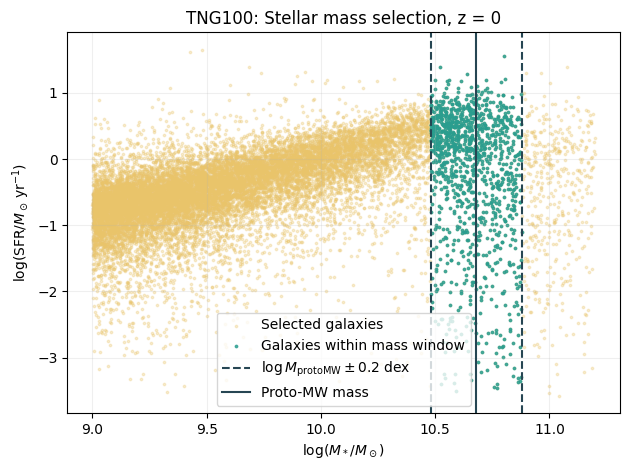

SNAPSHOT 50 | z = 1
Broj galaksija u selektovanom uzorku: 17412
Broj galaksija unutar masenog prozora: 1822


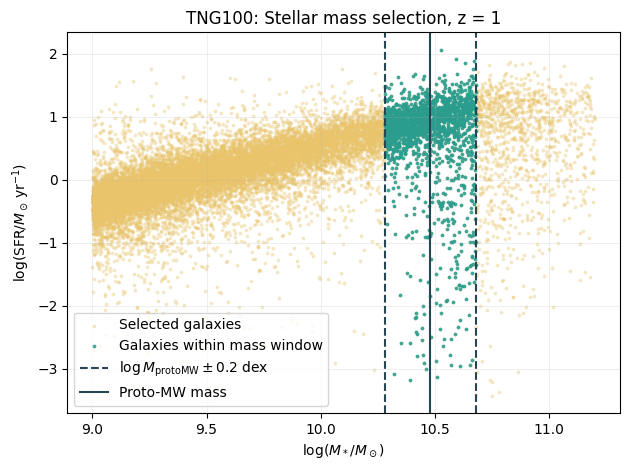

SNAPSHOT 33 | z = 2
Broj galaksija u selektovanom uzorku: 12254
Broj galaksija unutar masenog prozora: 1486


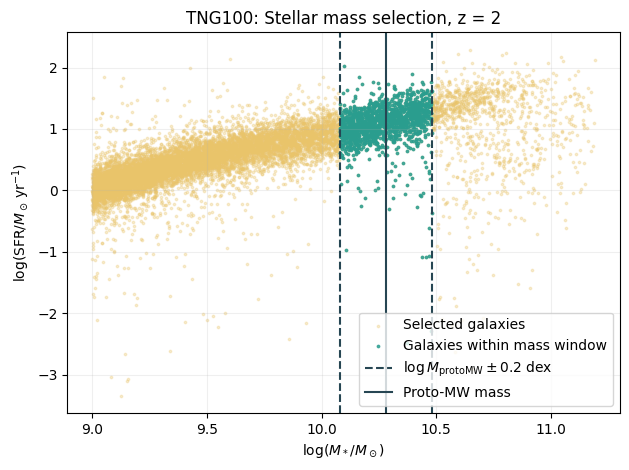

SNAPSHOT 25 | z = 3
Broj galaksija u selektovanom uzorku: 6738
Broj galaksija unutar masenog prozora: 1113


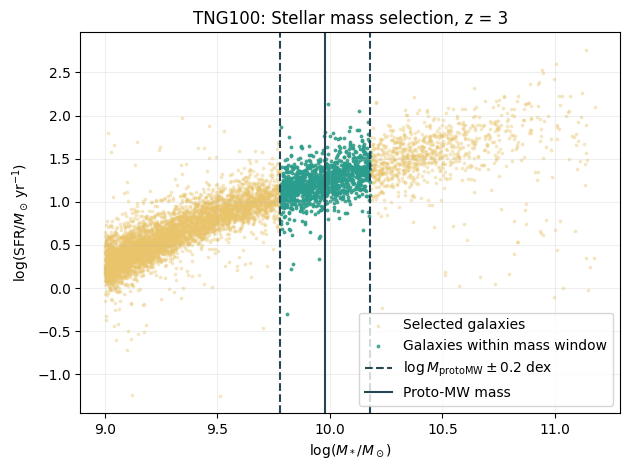

In [13]:
import numpy as np
import matplotlib.pyplot as plt

protoMWmass = [10.68, 10.48, 10.28, 9.98]

snapshot_redshifts = {
    99: 0,
    50: 1,
    33: 2,
    25: 3
}

h = 0.6774

mass_window_counts = {}
galaxies_in_mass_window = {}

for snap, z in snapshot_redshifts.items():

    data = filtered_data[snap]

    stellar_mass = data["SubhaloMassType"][:, 4]
    sfr = data["SubhaloSFR"]

    # Konverzija mase u Msun
    mass_msun = stellar_mass * 1e10 / h

    # Logaritamske vrednosti
    logM = np.full(len(mass_msun), np.nan)
    logSFR = np.full(len(sfr), np.nan)

    valid_mass = (
        np.isfinite(mass_msun) &
        (mass_msun > 0)
    )

    valid_sfr = (
        np.isfinite(sfr) &
        (sfr > 0)
    )

    logM[valid_mass] = np.log10(mass_msun[valid_mass])
    logSFR[valid_sfr] = np.log10(sfr[valid_sfr])

    # Zajednicki uslovi
    valid = (
        valid_mass &
        valid_sfr &
        (logM > 9) &
        (logM < 11.2) &
        (logSFR > -4)
    )

    # Proto-MW maseni prozor
    MW_mass = protoMWmass[z]

    lower_limit = MW_mass - 0.2
    upper_limit = MW_mass + 0.2

    mass_mask = (
        valid &
        (logM >= lower_limit) &
        (logM <= upper_limit)
    )

    galaxies_in_mass_window[z] = data["SubhaloID"][mass_mask]
    mass_window_counts[z] = np.sum(mass_mask)

    print(f"SNAPSHOT {snap} | z = {z}")
    print(f"Broj galaksija u selektovanom uzorku: {np.sum(valid)}")
    print(f"Broj galaksija unutar masenog prozora: {mass_window_counts[z]}")

    plt.figure()

    plt.scatter(
        logM[valid],
        logSFR[valid],
        s=3,
        alpha=0.3,
        color="#e9c46a",
        label="Selected galaxies"
    )

    plt.scatter(
        logM[mass_mask],
        logSFR[mass_mask],
        s=3,
        alpha=0.8,
        color="#2a9d8f",
        label="Galaxies within mass window"
    )

    plt.axvline(
        lower_limit,
        color="#264653",
        linestyle="--",
        linewidth=1.5,
        label=r"$\log M_{\mathrm{protoMW}} \pm 0.2$ dex"
    )

    plt.axvline(
        upper_limit,
        color="#264653",
        linestyle="--",
        linewidth=1.5
    )

    plt.axvline(
        MW_mass,
        color="#264653",
        linewidth=1.5,
        label="Proto-MW mass"
    )

    plt.xlabel(r"$\log(M_*/M_\odot)$")
    plt.ylabel(r"$\log(\mathrm{SFR}/M_\odot\,\mathrm{yr}^{-1})$")
    plt.title(f"TNG100: Stellar mass selection, z = {z}")

    plt.legend()
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()


SNAPSHOT 99 | z = 0
Ukupan selektovani uzorak: 17163
Aktivna populacija: 15952
Redukovana populacija: 1211
Sve galaksije u masenom prozoru: 1182
Aktivne galaksije u masenom prozoru: 849


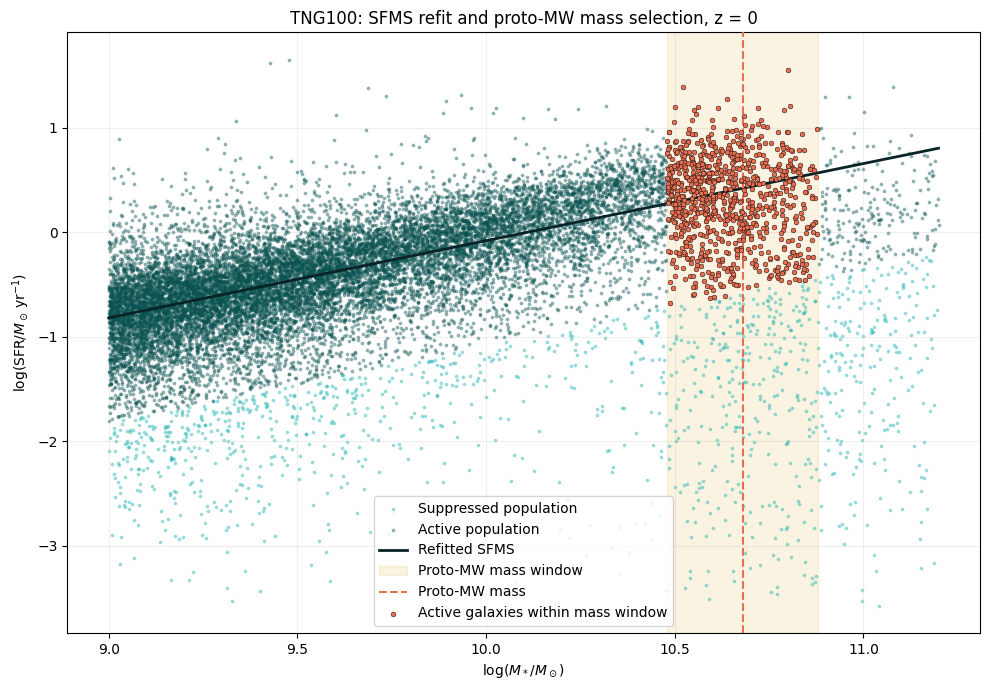


SNAPSHOT 50 | z = 1
Ukupan selektovani uzorak: 17412
Aktivna populacija: 16621
Redukovana populacija: 791
Sve galaksije u masenom prozoru: 1822
Aktivne galaksije u masenom prozoru: 1633


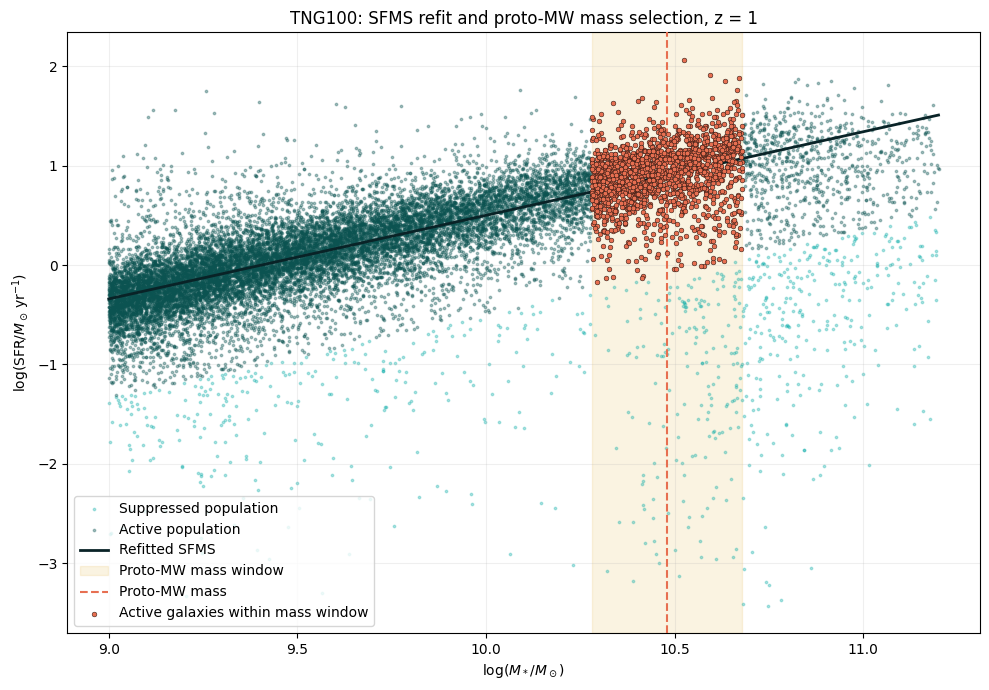


SNAPSHOT 33 | z = 2
Ukupan selektovani uzorak: 12254
Aktivna populacija: 11953
Redukovana populacija: 301
Sve galaksije u masenom prozoru: 1486
Aktivne galaksije u masenom prozoru: 1461


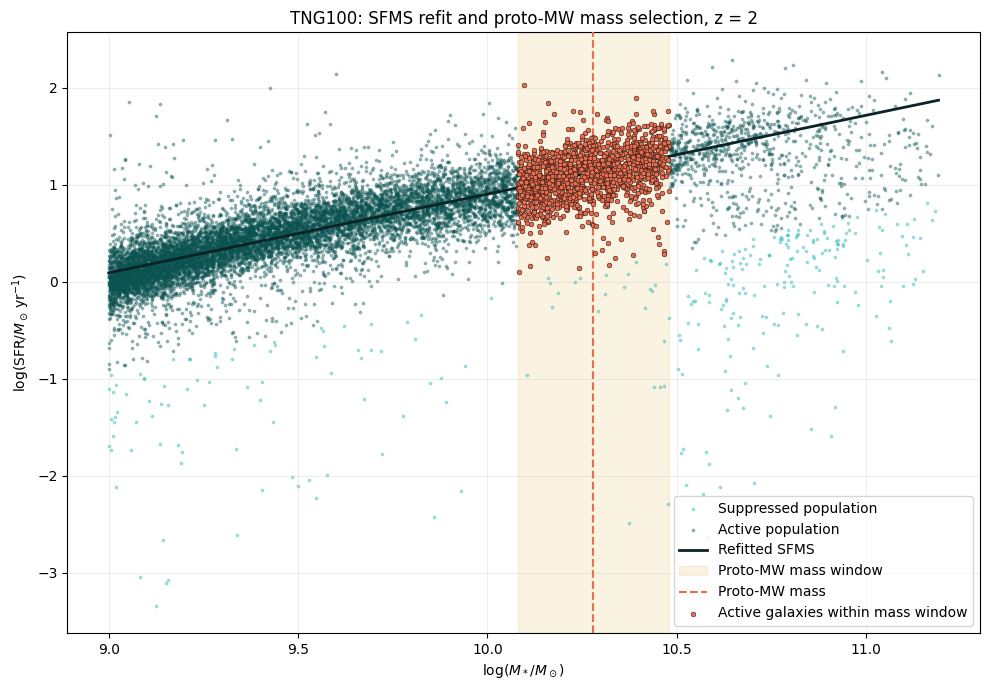


SNAPSHOT 25 | z = 3
Ukupan selektovani uzorak: 6738
Aktivna populacija: 6699
Redukovana populacija: 39
Sve galaksije u masenom prozoru: 1113
Aktivne galaksije u masenom prozoru: 1112


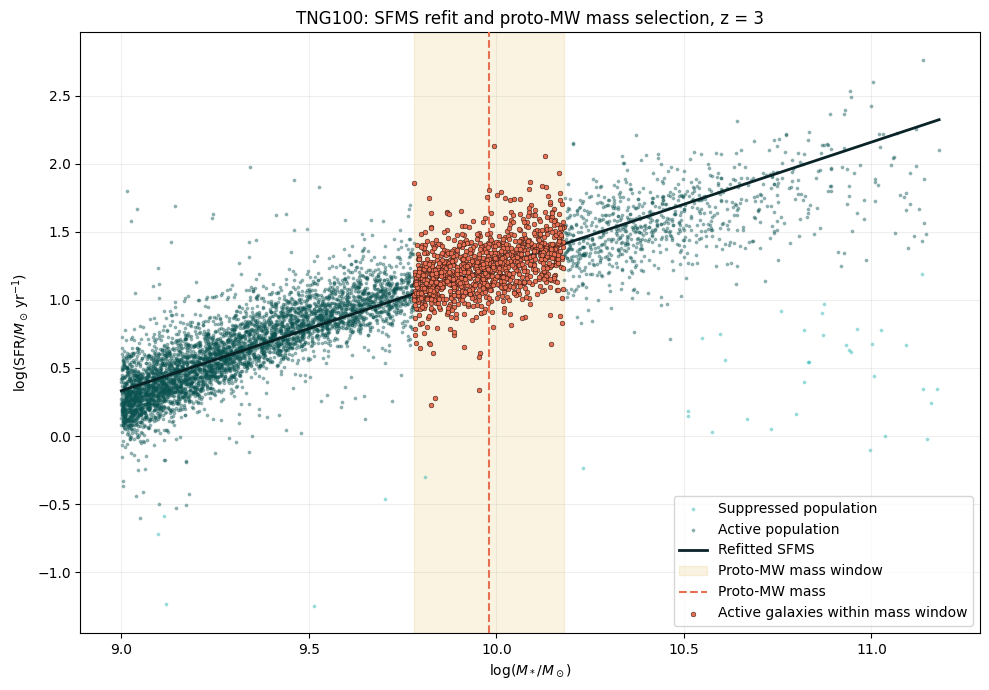

In [14]:
active_MW_counts = {}

active_MW_galaxies = {}

for snap, z in snapshot_redshifts.items():

    results = TNG_refit_results[z]

    df = results["all"]
    final_upper = results["final_upper"]
    final_lower = results["final_lower"]
    huber_refit = results["huber_refit"]

    MW_mass = protoMWmass[z]
    lower_limit = MW_mass - 0.2
    upper_limit = MW_mass + 0.2

    # Galaksije unutar proto-MW masenog prozora
    mass_mask = (
        (df["logM"] >= lower_limit) &
        (df["logM"] <= upper_limit)
    )

    # Aktivne galaksije prema refitovanoj SFMS
    active_mask = df["delta_refit"] > -1

    # Presek aktivne populacije i masenog prozora
    intersection_mask = mass_mask & active_mask

    intersection = df[intersection_mask].copy()

    active_MW_counts[z] = len(intersection)
    active_MW_galaxies[z] = intersection["id"].values

    N_active = active_mask.sum()
    N_reduced = (~active_mask).sum()
    N_mass = mass_mask.sum()
    N_intersection = intersection_mask.sum()

    print("\n" + "=" * 60)
    print(f"SNAPSHOT {snap} | z = {z}")
    print("=" * 60)

    print(f"Ukupan selektovani uzorak: {len(df)}")
    print(f"Aktivna populacija: {N_active}")
    print(f"Redukovana populacija: {N_reduced}")
    print(f"Sve galaksije u masenom prozoru: {N_mass}")
    print(f"Aktivne galaksije u masenom prozoru: {N_intersection}")

    # Refitted SFMS
    x_fit = np.linspace(df["logM"].min(), df["logM"].max(), 300)

    y_fit = (
        huber_refit.coef_[0] * x_fit
        + huber_refit.intercept_
    )

    plt.figure(figsize=(10, 7))

    plt.scatter(
        final_lower["logM"],
        final_lower["logSFR"],
        s=3,
        alpha=0.3,
        color="#00a9a5",
        label="Suppressed population",
        zorder=1
    )

    plt.scatter(
        final_upper["logM"],
        final_upper["logSFR"],
        s=3,
        alpha=0.35,
        color="#0b5351",
        label="Active population",
        zorder=2
    )

    plt.plot(
        x_fit,
        y_fit,
        color="#092327",
        linewidth=2,
        label="Refitted SFMS",
        zorder=3
    )

    plt.axvspan(
        lower_limit,
        upper_limit,
        color="#e9c46a",
        alpha=0.2,
        label="Proto-MW mass window",
        zorder=0
    )

    plt.axvline(
        MW_mass,
        color="#e76f51",
        linestyle="--",
        linewidth=1.5,
        label="Proto-MW mass",
        zorder=3
    )

    plt.scatter(
        intersection["logM"],
        intersection["logSFR"],
        s=12,
        color="#e76f51",
        edgecolors="black",
        linewidths=0.3,
        label="Active galaxies within mass window",
        zorder=5
    )

    plt.xlabel(r"$\log(M_*/M_\odot)$")
    plt.ylabel(r"$\log(\mathrm{SFR}/M_\odot\,\mathrm{yr}^{-1})$")
    plt.title(
        f"TNG100: SFMS refit and proto-MW mass selection, z = {z}"
    )

    plt.legend()
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()